# NE 630 - Lesson 25

In this supplemental notebook, we estimate $l_{\infty}$ for thermal neutrons in water using thermal cross-section data and using OpenMC.

# Part 1: Simple Estimate

What's $\ell_\infty$ for thermal neutrons in a giant pool of room-temperature
water? Use the lesson's approximate molecular absorption cross section
$\bar\sigma_a^{\mathrm{H_2O}}=0.6$ b and density $1.0$ g/cm$^3$.

Distinguish the speed at one energy, $v(0.0253\ \mathrm{eV})\simeq2200$ m/s,
from the **mean speed** for the Maxwellian flux spectrum in Example 1:

$$\bar v=\sqrt{\frac{8k_BT}{\pi m_n}},\qquad
\ell_\infty=\frac{1}{\bar\Sigma_a\bar v}.$$

The $0.6$-b value is a rounded, spectrum-averaged classroom input, not a
pointwise cross section. The two estimates below illustrate the effect of
the speed convention; the OpenMC calculation will use evaluated energy-dependent
data instead.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import Avogadro, Boltzmann, neutron_mass, electron_volt

T_water = 293.6                         # K
rho_water = 1.0                        # g/cm^3
N_water = rho_water * Avogadro / 18.0   # molecules/cm^3; rounded molar mass
Sigma_a_hand = N_water * 0.6e-24        # 1/cm
v_2200 = 100 * np.sqrt(2 * 0.0253 * electron_volt / neutron_mass)  # cm/s
v_Maxwell = 100 * np.sqrt(8 * Boltzmann * T_water / (np.pi * neutron_mass))
tau_2200 = 1 / (Sigma_a_hand * v_2200)   # s
tau_hand = 1 / (Sigma_a_hand * v_Maxwell)

print(f"Molecular number density: {N_water:.4e} cm^-3")
print(f"Classroom absorption cross section: {Sigma_a_hand:.5f} cm^-1")
print(f"Single-energy speed: {v_2200/100:.0f} m/s; lifetime: {tau_2200*1e6:.1f} us")
print(f"Maxwellian mean speed: {v_Maxwell/100:.0f} m/s; lifetime: {tau_hand*1e6:.1f} us")

Molecular number density: 3.3456e+22 cm^-3
Classroom absorption cross section: 0.02007 cm^-1
Single-energy speed: 2200 m/s; lifetime: 226.4 us
Maxwellian mean speed: 2483 m/s; lifetime: 200.7 us


## Part 2: OpenMC Model.

We use a 1-cm-radius reflecting water sphere and uniform, isotropic
2.45-MeV D–D neutron source, active from 0 to 1 ms. The sphere is a
**no-leakage surrogate**, not a physical 1-cm water sample or a model of a
detector. Hydrogen bound-in-water thermal scattering is included.

The historical experiment reported a water lifetime of $205 \pm 10$ $\mu$s
after accounting for diffusion ([Manley, Haworth, and Luebke, 1942](https://doi.org/10.1103/PhysRev.61.152)).
Here we compare with that scale, not reproduce the apparatus.

**Prediction:** once the source is off and slowing down is complete,
the population should approach a single exponential. In the one-group limit,

$$
   \frac{dn}{dt}=-\bar\Sigma_a\bar v\,n+S(t),\qquad
n=\phi/\bar v,\qquad \ell_\infty=(\bar\Sigma_a\bar v)^{-1}.
$$

In [2]:
import os
import tempfile
from pathlib import Path
import openmc
from scipy.optimize import curve_fit

water = openmc.Material(name="room-temperature water", temperature=T_water)
water.add_nuclide("H1", 2.0)
water.add_nuclide("O16", 1.0)
water.set_density("g/cm3", rho_water)
water.add_s_alpha_beta("c_H_in_H2O")

radius = 1.0  # cm; reflective boundary suppresses leakage
sphere = openmc.Sphere(r=radius, boundary_type="reflective")
cell = openmc.Cell(fill=water, region=-sphere)
cell.volume = 4 * np.pi * radius**3 / 3
model = openmc.Model(geometry=openmc.Geometry([cell]),
                     materials=openmc.Materials([water]))

t_off, t_max = 1e-3, 3e-3                    # s
S0 = 1.0                                     # physical source density, neutrons/(cm^3 s)
source_particles = S0 * cell.volume * t_off  # total emitted over the source pulse
model.settings.run_mode = "fixed source"
model.settings.source = openmc.IndependentSource(
    space=openmc.stats.spherical_uniform(r_outer=radius),
    angle=openmc.stats.Isotropic(),
    energy=openmc.stats.Discrete([2.45e6], [1.0]),
    time=openmc.stats.Uniform(0.0, t_off),
    strength=1.0,  # normalize the physical source explicitly in postprocessing
)
model.settings.batches = 60
model.settings.particles = 5000
model.settings.seed = 251025
model.settings.temperature = {"method": "nearest", "tolerance": 10.0}
model.settings.output = {"tallies": False}
print(f"{model.settings.batches * model.settings.particles:,} histories; "
      f"water {T_water} K, {rho_water} g/cm^3")

300,000 histories; water 293.6 K, 1.0 g/cm^3


### Time- and energy-resolved tallies

Use 10-μs bins and two energy groups: thermal ($E<1$ eV), then fast/epithermal
($E\geq1$ eV).

With source strength set to one, the tallies are integrated over cell volume
and time bin, per simulated source neutron. If $Q=S_0Vt_{\rm off}$,

$$\phi_{g,i}=\frac{QF_{g,i}}{V\Delta t_i},\qquad
R_{a,g,i}=\frac{QA_{g,i}}{V\Delta t_i},\qquad
n_{g,i}=\frac{QJ_{g,i}}{V\Delta t_i}.$$

Here $F$, $A$, and $J$ are the `flux`, `absorption`, and `inverse-velocity`
scores. Their units per source neutron are cm, dimensionless, and s,
respectively. Thus the plotted quantities have units cm$^{-2}$s$^{-1}$,
cm$^{-3}$s$^{-1}$, and cm$^{-3}$.
In particular, **$\bar v=F/J=\phi/n$**, not $1/J$.
See the [OpenMC tally definitions](https://docs.openmc.org/en/stable/usersguide/tallies.html).

An additional tally without a time filter checks total absorption and measures
the mean residence time from birth to absorption, including slowing down.

In [3]:
time_edges = np.linspace(0.0, t_max, 301)
dt = np.diff(time_edges)
t_mid = (time_edges[:-1] + time_edges[1:]) / 2
scores = ["flux", "absorption", "inverse-velocity"]
time_tally = openmc.Tally(name="water_time_energy")
time_tally.filters = [openmc.TimeFilter(time_edges),
                      openmc.EnergyFilter([0.0, 1.0, 20e6])]
time_tally.scores = scores
time_tally.estimator = "tracklength"
integral_tally = openmc.Tally(name="water_all_time")
integral_tally.scores = scores
integral_tally.estimator = "tracklength"
model.tallies = openmc.Tallies([time_tally, integral_tally])

with tempfile.TemporaryDirectory(prefix="ne630-water-lifetime-") as run_dir:
    statepoint_path = model.run(cwd=run_dir, threads=2, output=False)
    with openmc.StatePoint(statepoint_path) as sp:
        tally = sp.get_tally(name="water_time_energy")
        raw = tally.get_reshaped_data(value="mean")[:, :, 0, :].copy()
        raw_sd = tally.get_reshaped_data(value="std_dev")[:, :, 0, :].copy()
        integral = sp.get_tally(name="water_all_time")
        integral_mean = integral.mean[0, 0, :].copy()
        integral_sd = integral.std_dev[0, 0, :].copy()

scale = source_particles / (cell.volume * dt[:, None])
flux = raw[:, :, 0] * scale
absorption = raw[:, :, 1] * scale
density = raw[:, :, 2] * scale
flux_sd = raw_sd[:, :, 0] * scale
n_total = density.sum(axis=1)
Ra_total = absorption.sum(axis=1)
phi_total = flux.sum(axis=1)
print("Tally array: time bins, energy groups, scores =", raw.shape)
print(f"All-time absorptions/source neutron = {integral_mean[1]:.5f} "
      f"+/- {integral_sd[1]:.5f} (1 standard error)")
print(f"Mean birth-to-absorption time = {integral_mean[2]*1e6:.1f} "
      f"+/- {integral_sd[2]*1e6:.1f} us (1 standard error)")

Tally array: time bins, energy groups, scores = (300, 2, 3)
All-time absorptions/source neutron = 0.99795 +/- 0.00161 (1 standard error)
Mean birth-to-absorption time = 203.9 +/- 0.3 us (1 standard error)


### Watch the source turn on and off

The fast/epithermal population feeds the thermal population. A steady thermal
spectrum is not assumed during this startup; the Monte Carlo histories resolve
the slowing down and absorption. The one-group hand model is overlaid for
comparison and assumes instant thermalization.

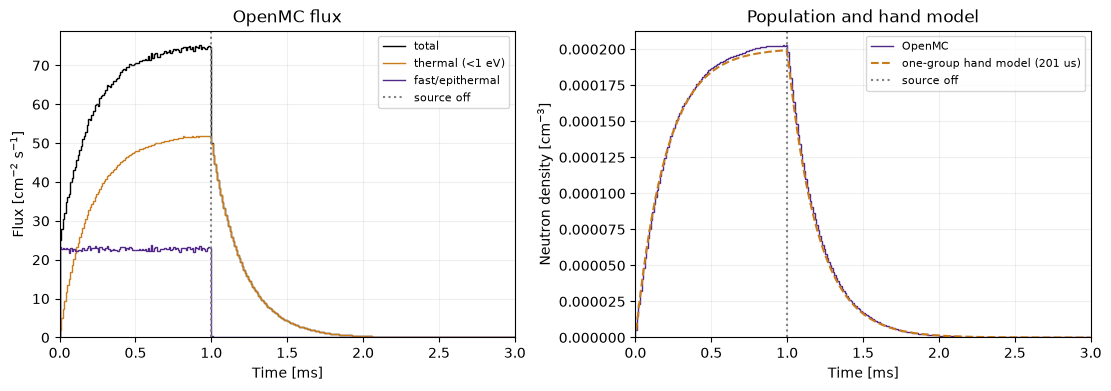

In [4]:
PURPLE, ORANGE = "#512888", "#CA7C1B"

def one_group_density(t, tau):
    t = np.asarray(t)
    buildup = S0 * tau * (-np.expm1(-np.minimum(t, t_off) / tau))
    return buildup * np.exp(-np.maximum(t - t_off, 0.0) / tau)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
axes[0].stairs(phi_total, time_edges * 1e3, color="black", label="total")
axes[0].stairs(flux[:, 0], time_edges * 1e3, color=ORANGE, label="thermal (<1 eV)")
axes[0].stairs(flux[:, 1], time_edges * 1e3, color=PURPLE, label="fast/epithermal")
axes[0].set(ylabel=r"Flux [cm$^{-2}$ s$^{-1}$]", title="OpenMC flux")
axes[1].stairs(n_total, time_edges * 1e3, color=PURPLE, label="OpenMC")
axes[1].plot(t_mid * 1e3, one_group_density(t_mid, tau_hand), "--", color=ORANGE,
             label=f"one-group hand model ({tau_hand*1e6:.0f} us)")
axes[1].set(ylabel=r"Neutron density [cm$^{-3}$]", title="Population and hand model")
for ax in axes:
    ax.axvline(t_off * 1e3, color="gray", ls=":", label="source off")
    ax.set(xlabel="Time [ms]", xlim=(0, t_max * 1e3))
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
plt.show()

### Extract the decay lifetime

Fit the **thermal flux** from 50 to 800 μs after shutoff, avoiding the immediate
slowing-down transient and the sparse far tail. Use the actual time-bin averages
of $A\exp[-(t-t_{\rm off})/\tau]$, rather than interpreting bin edges as samples.
The fit is weighted by the Monte Carlo standard error in each bin. Those bins
are correlated, so its covariance-derived parameter error is not reported as a
rigorous lifetime uncertainty.

For a second estimate, use tallies from 0.7–0.95 ms (near the end of the source
pulse): $\bar\Sigma_{a,T}=A_T/F_T$, $\bar v_T=F_T/J_T$, and
$\tau_T=J_T/A_T$. These are ratios of **integrated matching tallies**.
The all-time residence estimate includes the time before thermalization;
it need not be identical to the late-time exponential constant.

Thermal effective absorption: 0.01902 cm^-1
Thermal mean speed: 2574 m/s
Lifetime from thermal tally ratios: 204.3 us
Fitted thermal decay lifetime: 202.9 us
Classroom Maxwellian estimate: 200.7 us
Historical comparison: 205 +/- 10 us (not a fit constraint).


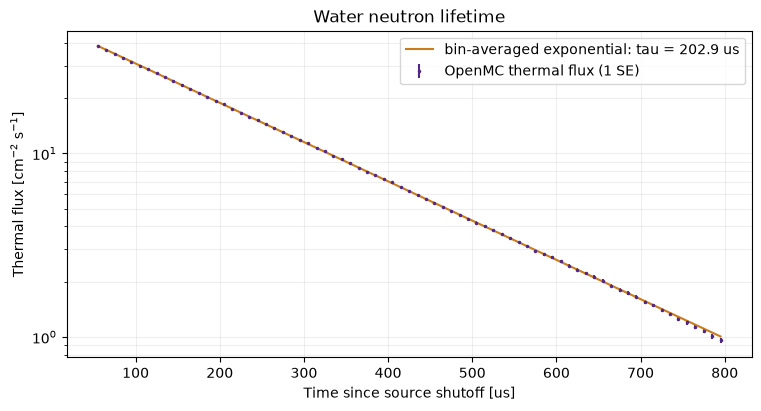

In [5]:
fit_start, fit_stop = t_off + 50e-6, t_off + 800e-6
fit_mask = ((time_edges[:-1] >= fit_start - 1e-12)
            & (time_edges[1:] <= fit_stop + 1e-12)
            & (flux[:, 0] > 0) & (flux_sd[:, 0] > 0))
lo_us = (time_edges[:-1][fit_mask] - t_off) * 1e6
hi_us = (time_edges[1:][fit_mask] - t_off) * 1e6

def bin_decay(bounds_us, amplitude, tau_us):
    lo, hi = bounds_us
    return amplitude * np.exp(-lo / tau_us) * (
        -np.expm1(-(hi - lo) / tau_us)) * tau_us / (hi - lo)

fit_parameters, fit_covariance = curve_fit(
    bin_decay, np.array([lo_us, hi_us]), flux[fit_mask, 0],
    sigma=flux_sd[fit_mask, 0], absolute_sigma=True,
    p0=(flux[fit_mask, 0][0], 200.0), bounds=([0, 1], [np.inf, 2000]),
)
amplitude, tau_fit_us = fit_parameters
tau_fit = tau_fit_us * 1e-6
plateau = (time_edges[:-1] >= 0.7e-3) & (time_edges[1:] <= 0.95e-3 + 1e-12)
F_T, A_T, J_T = raw[plateau, 0, :].sum(axis=0)
Sigma_a_T, v_T = A_T / F_T, F_T / J_T
tau_rates = J_T / A_T
print(f"Thermal effective absorption: {Sigma_a_T:.5f} cm^-1")
print(f"Thermal mean speed: {v_T/100:.0f} m/s")
print(f"Lifetime from thermal tally ratios: {tau_rates*1e6:.1f} us")
print(f"Fitted thermal decay lifetime: {tau_fit_us:.1f} us")
print(f"Classroom Maxwellian estimate: {tau_hand*1e6:.1f} us")
print("Historical comparison: 205 +/- 10 us (not a fit constraint).")

elapsed_us = (t_mid[fit_mask] - t_off) * 1e6
fig, ax = plt.subplots(figsize=(7.5, 4), layout="constrained")
ax.errorbar(elapsed_us, flux[fit_mask, 0], yerr=flux_sd[fit_mask, 0],
            fmt=".", ms=3, color=PURPLE, label="OpenMC thermal flux (1 SE)")
ax.plot(elapsed_us, bin_decay(np.array([lo_us, hi_us]), *fit_parameters),
        color=ORANGE, label=f"bin-averaged exponential: tau = {tau_fit_us:.1f} us")
ax.set(yscale="log", xlabel="Time since source shutoff [us]",
       ylabel=r"Thermal flux [cm$^{-2}$ s$^{-1}$]", title="Water neutron lifetime")
ax.grid(which="both", alpha=0.2)
ax.legend()
plt.show()

### Check the normalization and interpret the result

With no leakage or multiplication, every source neutron is eventually absorbed:
$\int R_a(t)\,dt=S_0t_{\rm off}$. At finite time, neutron balance is
$n(t)+\int_0^tR_a(t')\,dt'=\int_0^tS(t')\,dt'$.
The check below uses midpoint/bin-average quantities, so a small time-bin
discretization error remains in addition to Monte Carlo uncertainty.

**Discuss:** Why is the fast flux appreciable while its contribution to neutron
density is small? Why exclude the first few bins after shutoff from the fit?
How would a vacuum boundary change the measured decay time? Would changing the
source amplitude change the lifetime in this fixed-material model?

In [6]:
born_to_midpoint = S0 * np.minimum(t_mid, t_off)
absorbed_to_midpoint = np.cumsum(Ra_total * dt) - 0.5 * Ra_total * dt
balance_residual = n_total + absorbed_to_midpoint - born_to_midpoint
relative_balance_error = np.max(np.abs(balance_residual)) / (S0 * t_off)
absorbed_fraction = np.sum(Ra_total * dt) / (S0 * t_off)

assert np.isfinite(raw).all() and np.all(raw >= 0)
assert abs(integral_mean[1] - 1) < max(5 * integral_sd[1], 0.01)
assert relative_balance_error < 0.03
assert abs(tau_rates - 1 / (Sigma_a_T * v_T)) < 1e-12
print(f"Absorbed by {t_max*1e3:.1f} ms: {100*absorbed_fraction:.2f}% of emitted neutrons")
print(f"Maximum midpoint balance residual / emitted inventory: {relative_balance_error:.2%}")
print("Finite/nonnegative tallies, absorption normalization, and lifetime identity: passed.")

Absorbed by 3.0 ms: 99.79% of emitted neutrons
Maximum midpoint balance residual / emitted inventory: 0.25%
Finite/nonnegative tallies, absorption normalization, and lifetime identity: passed.
